# EDA

train_test.csv = labeled loads, Jan-Oct 2025. validation.csv = loads to predict, Nov-Dec 2025. Target is `posted_rate`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path("..") / "src"))
from features import TARGET, label_outliers, load_data

sns.set_theme(style="whitegrid")
train, valid, december = load_data()
train["rpm"] = train[TARGET] / train["distance"]
print(train.shape, valid.shape, december.shape)
train.head()

(48000, 15) (12000, 13) (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rpm
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,2.352935
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,2.424135
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1.862513
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1.892770
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,2.547112


In [2]:
train.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
load_id,48000,48000,TR-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup,48000,64,Oklahoma City,1242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delivery,48000,64,Lexington,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_lat,48000.0,NaN,NaN,NaN,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,NaN,NaN,NaN,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,NaN,NaN,NaN,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,NaN,NaN,NaN,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,NaN,NaN,NaN,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
equipment,48000,3,Dry Van,27202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,47700.0,NaN,NaN,NaN,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062


## Data quality

In [3]:
pd.DataFrame({"train_missing": train.isna().sum(), "valid_missing": valid.isna().sum()}).query("train_missing > 0 or valid_missing > 0")

,train_missing,valid_missing
market_index,374,249.0
weight,300,165.0


In [4]:
print("duplicate load_id:", train["load_id"].duplicated().sum(), valid["load_id"].duplicated().sum())
print("duplicate feature rows:", train.drop(columns=["load_id", TARGET, "rpm"]).duplicated().sum())
print("equipment values:", sorted(train["equipment"].unique()))
coords = pd.concat([train.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max(axis=1),
                    train.groupby("delivery")[["delivery_lat", "delivery_lon"]].nunique().max(axis=1)])
print("cities with more than one coordinate:", (coords > 1).sum())

duplicate load_id: 0 0
duplicate feature rows: 0
equipment values: ['Dry Van', 'Flatbed', 'Reefer']
cities with more than one coordinate: 0


### Weight
Negative weights price like their absolute value, so probably sign errors. 47,500 shows up way more than any other value, looks like a cap.

In [5]:
band = pd.qcut(train["distance"], 10, labels=False)
ratio = train["rpm"] / train["rpm"].groupby([train["equipment"], band]).transform("median")
groups = {"negative": train["weight"] < 0, "missing": train["weight"].isna(),
          "exactly 47,500": train["weight"] == 47_500, "normal": train["weight"].between(1, 47_499)}
pd.DataFrame({"rows (train)": {k: m.sum() for k, m in groups.items()},
              "median rate vs comparable loads": {k: ratio[m].median() for k, m in groups.items()}}).round(3)

,rows (train),median rate vs comparable loads
negative,292,1.002
missing,300,0.999
"exactly 47,500",1191,1.033
normal,46217,0.999


### Distance vs great-circle
Road miles should be roughly 1.2x the straight-line distance.

count    48000.000
mean         1.195
std          0.144
min          1.058
1%           1.130
50%          1.182
99%          1.404
max          9.635
dtype: float64
distance / lane median: min 0.76, max 1.28


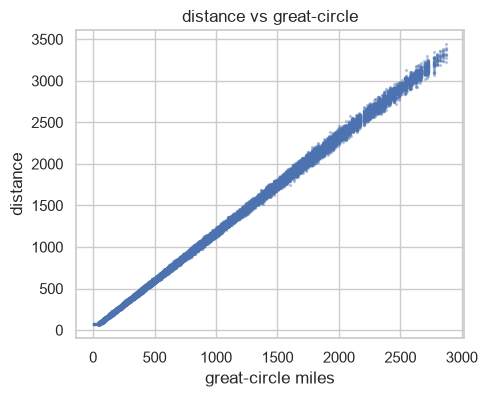

In [6]:
def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

great_circle = haversine_miles(train.pickup_lat, train.pickup_lon, train.delivery_lat, train.delivery_lon)
print((train["distance"] / great_circle).describe(percentiles=[.01, .5, .99]).round(3))
lane_dev = train["distance"] / train.groupby(["pickup", "delivery"])["distance"].transform("median")
print("distance / lane median: min %.2f, max %.2f" % (lane_dev.min(), lane_dev.max()))
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(great_circle, train["distance"], s=2, alpha=0.3)
ax.set(xlabel="great-circle miles", ylabel="distance", title="distance vs great-circle"); plt.show()

Distances are consistent within each lane. The high ratios are just short lanes where the two cities' coordinates are close together. Leaving distance as is.

### Outlier rates
~1.5% of rates are 0.2-0.4x or 3-5x what similar loads pay, with little in between. Looks like corrupted labels.

flagged: 677 rows (1.4%)


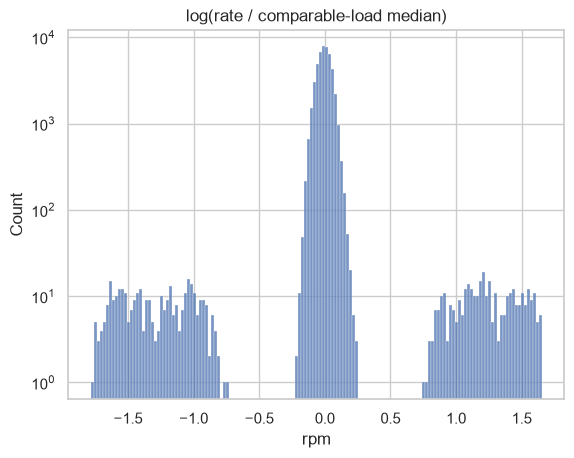

In [7]:
flag = label_outliers(train)
print(f"flagged: {flag.sum()} rows ({flag.mean():.1%})")
sns.histplot(np.log(ratio), bins=150).set(yscale="log", title="log(rate / comparable-load median)"); plt.show()

## Target

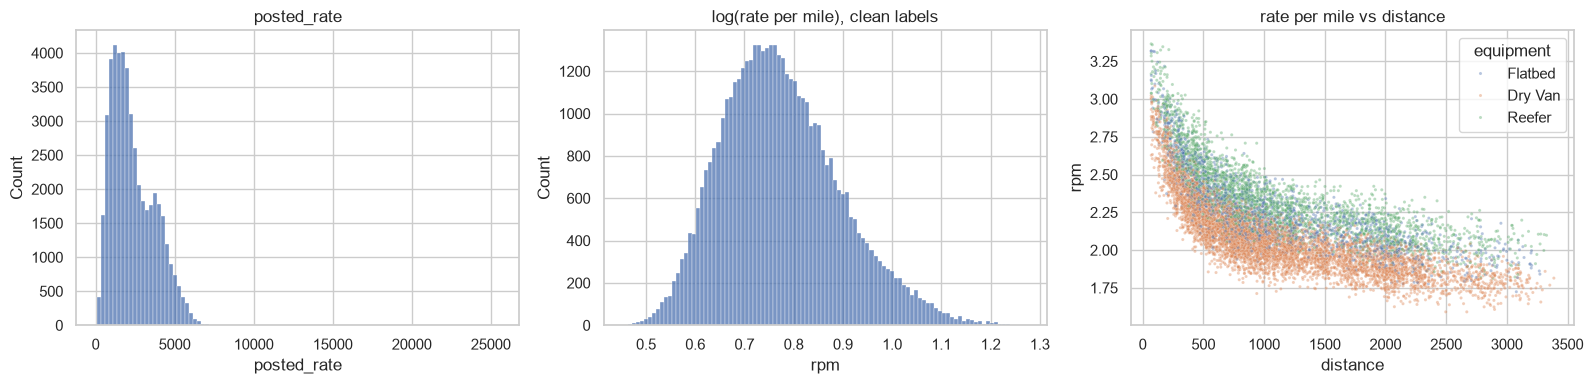

equipment
Dry Van    2.046
Flatbed    2.220
Reefer     2.312
Name: rpm, dtype: float64

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train[TARGET], bins=100, ax=axes[0]).set(title="posted_rate")
sns.histplot(np.log(train.loc[~flag, "rpm"]), bins=100, ax=axes[1]).set(title="log(rate per mile), clean labels")
sample = train[~flag].sample(10_000, random_state=0)
sns.scatterplot(data=sample, x="distance", y="rpm", hue="equipment", s=5, alpha=0.4, ax=axes[2]).set(title="rate per mile vs distance")
plt.tight_layout(); plt.show()
train.loc[~flag].groupby("equipment")["rpm"].median().round(3)

Distance explains most of the price. Rate per mile drops with distance (fixed costs per load). Modeling log(rate per mile).

## Market index over time

corr(within-day market_index deviation, within-day rate deviation): 0.033


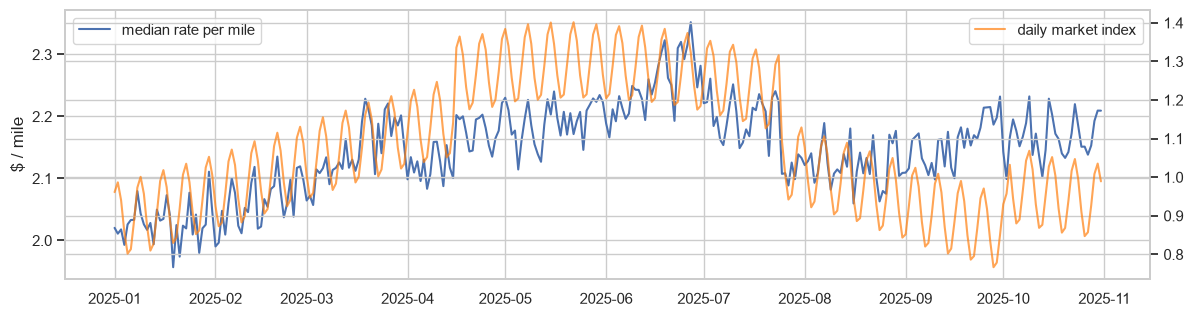

In [9]:
within_day = train["market_index"] - train.groupby("date")["market_index"].transform("mean")
rpm_within_day = train["rpm"] - train.groupby("date")["rpm"].transform("median")
ok = within_day.notna() & ~flag
print("corr(within-day market_index deviation, within-day rate deviation):", round(np.corrcoef(within_day[ok], rpm_within_day[ok])[0, 1], 3))

daily = train[~flag].groupby("date").agg(rpm=("rpm", "median"))
daily["market_index"] = pd.concat([train, valid]).groupby("date")["market_index"].mean()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(daily.index, daily["rpm"], label="median rate per mile"); ax.set_ylabel("$ / mile")
ax2 = ax.twinx(); ax2.plot(daily.index, daily["market_index"], color="tab:orange", alpha=0.7, label="daily market index")
ax.legend(loc="upper left"); ax2.legend(loc="upper right"); plt.show()

- Within a day, a load's market_index deviation doesn't relate to its rate, so I use the daily mean.
- Rates follow the weekly cycle and the spring peak, but also drift in ways the index doesn't explain (spring rise, soft Jul-Aug, jump in Sep). That level is the hard part to forecast.

## quote_signal
Near-zero correlation with the rate overall, but the scatter is an X. Splitting by month:

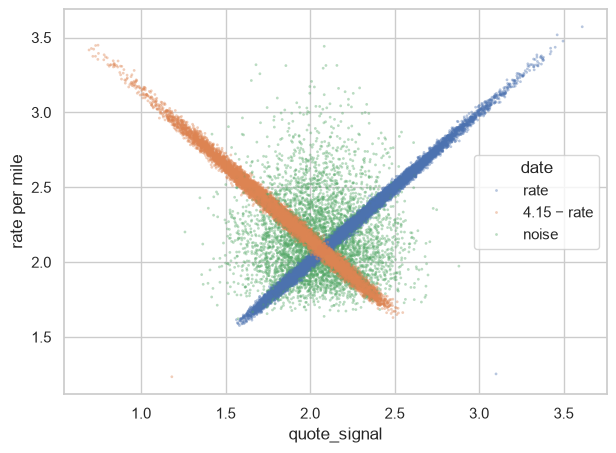

,slope,intercept,corr,regime
date,,,,
1,1.000,-0.001,0.996,rate
2,0.994,0.014,0.990,rate
3,1.001,-0.002,0.997,rate
4,-1.002,4.154,-0.993,4.15 − rate
5,-0.995,4.138,-0.989,4.15 − rate
6,0.999,0.002,0.997,rate
7,-0.999,4.147,-0.994,4.15 − rate
8,-0.017,2.090,-0.020,noise
9,1.000,0.000,0.997,rate


In [10]:
t = train[train["rpm"].between(1.2, 4)]
by_month = t.groupby(t["date"].dt.month).apply(
    lambda g: pd.Series({"slope": np.polyfit(g["rpm"], g["quote_signal"], 1)[0],
                         "intercept": np.polyfit(g["rpm"], g["quote_signal"], 1)[1],
                         "corr": np.corrcoef(g["rpm"], g["quote_signal"])[0, 1]}), include_groups=False)
by_month["regime"] = np.select([by_month["corr"] > 0.5, by_month["corr"] < -0.5], ["rate", "4.15 − rate"], "noise")
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=t["quote_signal"], y=t["rpm"], hue=t["date"].dt.month.map(by_month["regime"]), s=4, alpha=0.4, linewidth=0, ax=ax)
ax.set(ylabel="rate per mile"); plt.show()
by_month.round(3)

Which pattern do Nov-Dec follow? Can check without labels by comparing quote_signal to a rough rate estimate from distance, equipment and weight. This recovers the training months correctly.

In [11]:
from sklearn.linear_model import HuberRegressor

def proxy_design(df):
    return np.c_[100 / df["distance"], np.log(df["distance"]), df["weight"].abs().fillna(31_000) / 1000,
                 df["equipment"].eq("Flatbed"), df["equipment"].eq("Reefer")]

proxy = HuberRegressor(max_iter=2000).fit(proxy_design(train[~flag]), np.log(train.loc[~flag, "rpm"]))
both = pd.concat([train.assign(file="train"), valid.assign(file="validation")], ignore_index=True)
both["proxy"] = proxy.predict(proxy_design(both))
both.groupby(["file", both["date"].dt.month]).apply(lambda g: g["quote_signal"].corr(g["proxy"]), include_groups=False).unstack().round(2)

date,1,2,3,4,5,6,7,8,9,10,11,12
file,,,,,,,,,,,,
train,0.95,0.95,0.94,-0.94,-0.95,0.95,-0.94,-0.02,0.95,-0.95,NaN,NaN
validation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-0.01


Nov and Dec are noise months, so quote_signal tells us nothing about the loads we need to predict. It would help in CV (most test months have the signal) and then fail on Nov-Dec. Dropping it.

Side note: in the signal months it gives a normal price for the outlier rows, so those labels are wrong rather than the loads being unusual.

In [12]:
regime = train["date"].dt.month.map(by_month["regime"])
implied = np.where(regime == "rate", train["quote_signal"], np.where(regime == "4.15 − rate", 4.15 - train["quote_signal"], np.nan))
pd.DataFrame({"normal labels": (train["rpm"] / implied)[~flag].describe(percentiles=[.1, .5, .9]),
              "flagged labels": (train["rpm"] / implied)[flag].describe(percentiles=[.1, .5, .9])}).round(2).T

,count,mean,std,min,10%,50%,90%,max
normal labels,42632.0,1.00,0.01,0.95,0.99,1.00,1.02,1.06
flagged labels,609.0,1.92,1.72,0.18,0.21,2.26,4.36,5.10


## Nov-Dec vs training

In [13]:
print(pd.concat({"train": train["equipment"].value_counts(normalize=True),
                 "valid": valid["equipment"].value_counts(normalize=True)}, axis=1).round(3))
print(f"market_index range: train {train.market_index.min():.2f}-{train.market_index.max():.2f}, valid {valid.market_index.min():.2f}-{valid.market_index.max():.2f}")
known = set(train["pickup"]) | set(train["delivery"])
new = sorted((set(valid["pickup"]) | set(valid["delivery"])) - known)
print("cities only in validation:", new)
print("validation rows touching them:", (~valid["pickup"].isin(known) | ~valid["delivery"].isin(known)).sum())

           train  valid
equipment              
Dry Van    0.567  0.565
Reefer     0.251  0.254
Flatbed    0.182  0.181
market_index range: train 0.68-1.47, valid 0.72-1.10
cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation rows touching them: 1447


## Summary

| Finding | What I did |
|---|---|
| Negative weights (292 train / 145 valid) | abs() |
| Missing weight (300 / 165) | median by equipment + flag |
| 47,500 lb cap (1,191 rows) | keep + flag |
| market_index is daily level + noise, 374 / 249 missing | daily mean |
| quote_signal leaks the target, noise in Nov-Dec | dropped |
| ~1.5% corrupted labels | dropped from training, also report MAE without them |
| distance vs coordinates | fine |
| 8 new cities in validation (~12% of rows) | coordinates + city dummies |
| predicting 1-61 days past the last label | time-based validation |